<a href="https://colab.research.google.com/github/Killeryoung/ML/blob/main/%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%B5_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_ML_%D0%B4%D0%B6%D1%83%D0%BD%D1%96%D0%BE%D1%80_%D0%93%D1%83%D1%80%D0%BA%D0%BE_%D0%94%D0%B0%D0%BD%D0%B8%D0%BB%D0%BE_%D0%A4%D0%86%D0%A2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Прогнозування відтоку клієнтів (Customer Churn)
**Мета** - спрогнозувати, чи відмовиться клієнт від послуг телекомунікаційної компанії.

**Опис роботи:** У цій роботі я використовую датасет Telco Customer Churn із Kaggle, який містить інформацію про 7043 клієнтів. На основі цих даних потрібно навчити модель визначати, чи залишиться клієнт у компанії, чи перестане користуватися її послугами.

**Основні завдання:**

1. Завантажити та проаналізувати датасет.

2. Підготувати дані для навчання моделей.

3. Навчити три моделі машинного навчання.

4. Порівняти їхні результати та вибрати найкращу.

5. Перевірити прогноз на новому клієнті.

**Використані інструменти:** Python, Google Colab, KaggleHub, Pandas, Scikit-learn, Matplotlib, Seaborn.

## 1. Встановлення бібліотек

In [1]:
!pip -q install kagglehub pandas numpy matplotlib seaborn scikit-learn

## 2. Завантаження датасету з KaggleHub

In [2]:
import kagglehub, pandas as pd, numpy as np, os
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
files = [os.path.join(root, f) for root, _, names in os.walk(path) for f in names if f.lower().endswith(".csv")]
assert files, "CSV-файл не знайдено"
df = pd.read_csv(files[0])
print("Джерело:", files[0]); print("Розмір:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Джерело: /kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
Розмір: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Первинний аналіз даних

Типи даних і заповненість:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBillin

,Кількість
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Статистика:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Розподіл цільової ознаки:


,proportion
Churn,
No,73.46
Yes,26.54


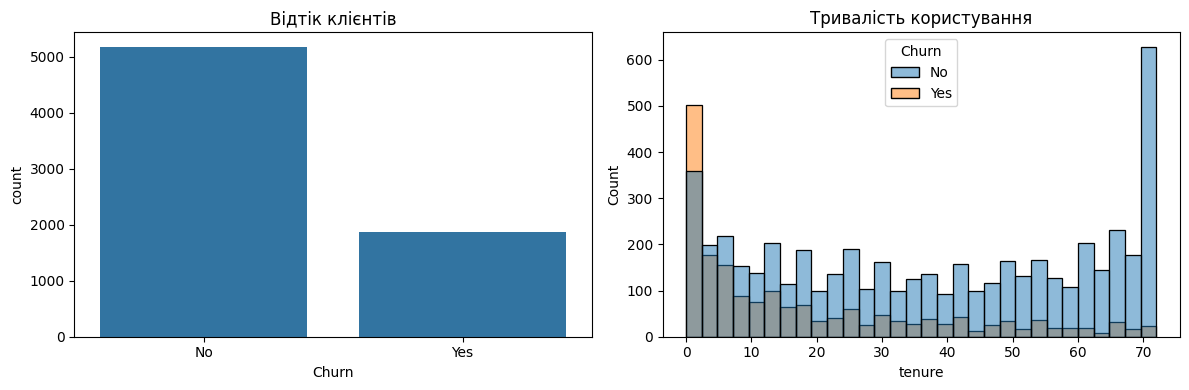

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
print("Типи даних і заповненість:")
df.info()
print("\nПропуски:"); display(df.isna().sum().to_frame("Кількість"))
print("\nСтатистика:"); display(df.describe(include="all").T)
print("\nРозподіл цільової ознаки:"); display(df["Churn"].value_counts(normalize=True).mul(100).round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Churn", ax=axes[0]); axes[0].set_title("Відтік клієнтів")
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[1]); axes[1].set_title("Тривалість користування")
plt.tight_layout(); plt.show()

## 4. Підготовка даних і поділ на вибірки
Заповнення пропусків, стандартизація числових ознак та one-hot кодування категорій виконуються всередині Pipeline, щоб уникнути витоку даних.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

data = df.copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
print("Пропуски після перетворення TotalCharges:", data["TotalCharges"].isna().sum())
X = data.drop(columns=["customerID", "Churn"])
y = data["Churn"].map({"No": 0, "Yes": 1})
assert y.notna().all(), "Невідомі значення Churn"
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X.select_dtypes(include=["number"]).columns.tolist()
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Навчальна:", X_train.shape, "Тестова:", X_test.shape)

Пропуски після перетворення TotalCharges: 11
Навчальна: (5634, 19) Тестова: (1409, 19)


## 5. Навчання трьох моделей та порівняння

,Модель,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
2,Random Forest,0.7807,0.6117,0.4759,0.5353
1,Decision Tree,0.7289,0.4896,0.5053,0.4974


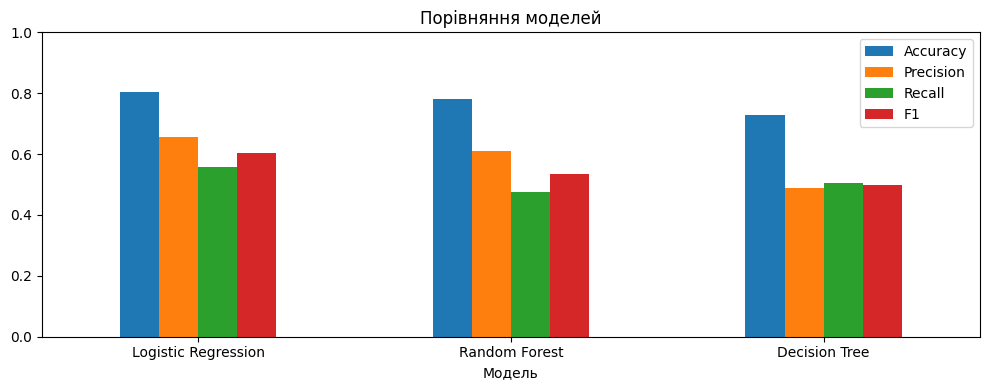

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

algorithms = {
    "Logistic Regression": LogisticRegression(max_iter=1500, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
}
trained_models = {}
results = []
def evaluate(name, model):
    p = model.predict(X_test)
    return {"Модель": name, "Accuracy": accuracy_score(y_test, p),
            "Precision": precision_score(y_test, p, zero_division=0),
            "Recall": recall_score(y_test, p, zero_division=0),
            "F1": f1_score(y_test, p, zero_division=0)}
for name, classifier in algorithms.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", classifier)])
    pipe.fit(X_train, y_train)
    trained_models[name] = pipe
    results.append(evaluate(name, pipe))
results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
display(results_df.round(4))
results_df.set_index("Модель")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 4), ylim=(0, 1), rot=0)
plt.title("Порівняння моделей"); plt.tight_layout(); plt.show()

## 6. Підбір гіперпараметрів Random Forest
Пошук виконується лише на навчальній вибірці з 3-кратною кросвалідацією.

In [6]:
from sklearn.model_selection import GridSearchCV
rf_pipe = Pipeline([("preprocessor", preprocessor), ("classifier", RandomForestClassifier(random_state=42, n_jobs=1))])
param_grid = {"classifier__n_estimators": [100, 200], "classifier__max_depth": [5, 10, None], "classifier__min_samples_leaf": [1, 3]}
search = GridSearchCV(rf_pipe, param_grid, scoring="f1", cv=3, n_jobs=-1)
search.fit(X_train, y_train)
print("Оптимальні параметри:", search.best_params_)
print("F1 кросвалідації:", round(search.best_score_, 4))
trained_models["Random Forest Tuned"] = search.best_estimator_
results.append(evaluate("Random Forest Tuned", search.best_estimator_))
results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
display(results_df.round(4))

Оптимальні параметри: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 100}
F1 кросвалідації: 0.5826


,Модель,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,Random Forest Tuned,0.8013,0.6655,0.5053,0.5745
2,Random Forest,0.7807,0.6117,0.4759,0.5353
3,Decision Tree,0.7289,0.4896,0.5053,0.4974


## 7. Вибір найкращої моделі та оцінювання
Для навчальної роботи найкращу модель обираємо за тестовим F1. Для строгого незалежного оцінювання модель слід обирати за кросвалідацією на навчальній вибірці, а тест використовувати лише один раз.

Найкраща модель за F1: Logistic Regression
              precision    recall  f1-score   support

  Залишиться       0.85      0.89      0.87      1035
        Піде       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



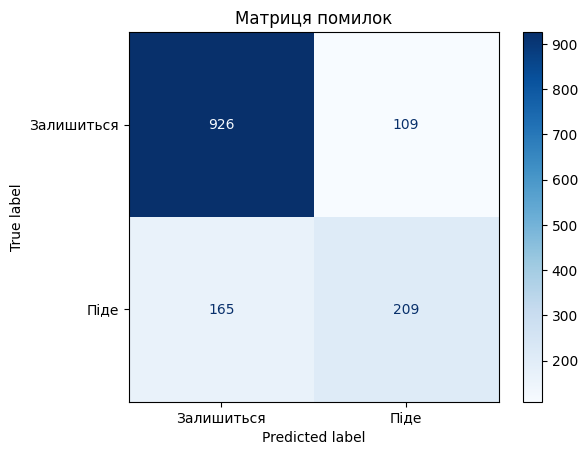

In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
best_name = results_df.iloc[0]["Модель"]
best_model = trained_models[best_name]
print("Найкраща модель за F1:", best_name)
print(classification_report(y_test, best_model.predict(X_test), target_names=["Залишиться", "Піде"], zero_division=0))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=["Залишиться", "Піде"], cmap="Blues")
plt.title("Матриця помилок"); plt.show()

## 8. Прогноз для нового клієнта
Нижче можна ввести всі характеристики клієнта через інтерактивні поля. Типові значення задані для демонстрації.

In [10]:
gender = "Female"
SeniorCitizen = 0
Partner = "No"
Dependents = "No"
tenure = 6
PhoneService = "Yes"
MultipleLines = "No"
InternetService = "Fiber optic"
OnlineSecurity = "No"
OnlineBackup = "No"
DeviceProtection = "No"
TechSupport = "No"
StreamingTV = "Yes"
StreamingMovies = "Yes"
Contract = "Month-to-month"
PaperlessBilling = "Yes"
PaymentMethod = "Electronic check"
MonthlyCharges = 85.0
TotalCharges = 510.0

client = pd.DataFrame([{k: v for k, v in {
    "gender": gender, "SeniorCitizen": SeniorCitizen, "Partner": Partner,
    "Dependents": Dependents, "tenure": tenure, "PhoneService": PhoneService,
    "MultipleLines": MultipleLines, "InternetService": InternetService,
    "OnlineSecurity": OnlineSecurity, "OnlineBackup": OnlineBackup,
    "DeviceProtection": DeviceProtection, "TechSupport": TechSupport,
    "StreamingTV": StreamingTV, "StreamingMovies": StreamingMovies,
    "Contract": Contract, "PaperlessBilling": PaperlessBilling,
    "PaymentMethod": PaymentMethod, "MonthlyCharges": MonthlyCharges,
    "TotalCharges": TotalCharges
}.items()}])
client = client[X.columns]
assert SeniorCitizen in (0, 1) and tenure >= 0 and MonthlyCharges >= 0 and TotalCharges >= 0
pred = int(best_model.predict(client)[0])
prob = float(best_model.predict_proba(client)[0, 1])
print("Прогноз:", "КЛІЄНТ ПІДЕ" if pred else "КЛІЄНТ ЗАЛИШИТЬСЯ")
print(f"Оцінена ймовірність відтоку: {prob:.1%}")

Прогноз: КЛІЄНТ ПІДЕ
Оцінена ймовірність відтоку: 77.6%


### 9. Висновки
У цій роботі я використав дані клієнтів компанії, щоб визначити, хто може перестати користуватися її послугами. Спочатку я перевірив дані та підготував їх для навчання моделей, після чого навчив три різні моделі та порівняв їхні результати. Найкраще себе показала модель Logistic Regression, яка краще за інші впоралася з прогнозуванням відтоку клієнтів. Наприкінці я ввів дані клієнта й отримав прогноз, чи залишиться він у компанії, а також побачив ймовірність його відтоку. Завдяки цій роботі я зрозумів, як можна використовувати машинне навчання для аналізу даних і прогнозування поведінки клієнтів.